# 04 — Scale-Space Construction

Uses the **real, computed GSD** from Notebook 03 (`estimated_gsd_m`) for OHRC
and TMC-2 when available, falling back to nominal mission values only when a
product lacks georeferencing (this is IIRS's situation in your download, and
any OHRC/TMC-2 product where GCP loading failed).


In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=False)

import os, csv, math
import numpy as np
import rasterio
import cv2
import matplotlib.pyplot as plt

DRIVE_ROOT = '/content/drive/MyDrive/26166_DATA'
OUT_ROOT   = f'{DRIVE_ROOT}/processed/scalespace'
os.makedirs(OUT_ROOT, exist_ok=True)

# Source pixel data now comes from 03b's common-footprint crops, not the
# full-strip radiometric products — see 03b_common_footprint_crop.ipynb.
with open(f'{DRIVE_ROOT}/processed/manifest_common_crop.csv') as f:
    common_rows = list(csv.DictReader(f))

with open(f'{DRIVE_ROOT}/processed/manifest_radiometric.csv') as f:
    radio_rows = list(csv.DictReader(f))

geocoded_rows = []
geocoded_manifest = f'{DRIVE_ROOT}/processed/manifest_geocoded.csv'
if os.path.exists(geocoded_manifest):
    with open(geocoded_manifest) as f:
        geocoded_rows = list(csv.DictReader(f))

NOMINAL_GSD_M = {'ohrc': 0.3, 'tmc2': 5.0, 'iirs': 80.0}   # fallback only

def get_gsd(instrument, product):
    match = next((r for r in geocoded_rows if r['instrument'] == instrument and r['product'] == product), None)
    if match and match.get('estimated_gsd_m'):
        try:
            return float(match['estimated_gsd_m']), 'measured'
        except ValueError:
            pass
    return NOMINAL_GSD_M[instrument], 'nominal'

def get_product_name(instrument):
    match = next((r for r in geocoded_rows if r['instrument'] == instrument), None)
    if match:
        return match['product']
    match = next((r for r in radio_rows if r['instrument'] == instrument), None)
    return match['product'] if match else None

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Pyramid helpers (unchanged from before)

In [2]:
def build_pyramid(img_u8, n_levels):
    pyramid = [img_u8]
    current = img_u8
    for _ in range(n_levels):
        current = cv2.pyrDown(current)
        pyramid.append(current)
    return pyramid

def gsd_at_level(base_gsd, level):
    return base_gsd * (2 ** level)

def best_level_for_target_gsd(base_gsd, target_gsd, max_levels=10):
    best_level, best_diff = 0, float('inf')
    for level in range(max_levels + 1):
        diff = abs(gsd_at_level(base_gsd, level) - target_gsd)
        if diff < best_diff:
            best_level, best_diff = level, diff
    return best_level

def load_gray(path):
    with rasterio.open(path) as src:
        return src.read(1)

def get_common_path(pair, role):
    """role is 'fine' or 'coarse' — sourced from 03b's common-footprint crop,
    not the full strip."""
    match = next((r for r in common_rows if r['pair'] == pair and r['role'] == role), None)
    assert match, f'No common-crop product for pair={pair} role={role} — run 03b first.'
    return match['common_path'], match['instrument']

## 2. Compute pyramid levels using real (measured) GSD where possible

In [3]:
pairings = [('ohrc', 'tmc2'), ('tmc2', 'iirs')]
scalespace_manifest = []

for fine, coarse in pairings:
    pair_name = f'{fine}_to_{coarse}'
    fine_path, fine_instrument = get_common_path(pair_name, 'fine')
    coarse_path, coarse_instrument = get_common_path(pair_name, 'coarse')
    assert fine_instrument == fine and coarse_instrument == coarse, \
        f'Manifest role mismatch for {pair_name} — check 03b output.'

    fine_product = get_product_name(fine)
    coarse_product = get_product_name(coarse)
    fine_gsd, fine_src = get_gsd(fine, fine_product)
    coarse_gsd, coarse_src = get_gsd(coarse, coarse_product)
    level = best_level_for_target_gsd(fine_gsd, coarse_gsd)
    achieved = gsd_at_level(fine_gsd, level)

    print(f'{fine} ({fine_gsd:.3f} m/px, {fine_src}) -> {coarse} ({coarse_gsd:.3f} m/px, {coarse_src}): '
          f'pyramid level {level} (achieved {achieved:.3f} m/px)')

    with rasterio.open(fine_path) as src:
        fine_img = src.read(1)
        fine_crs, fine_transform = src.crs, src.transform
    pyramid = build_pyramid(fine_img, n_levels=level)
    fine_scaled = pyramid[level]

    with rasterio.open(coarse_path) as src:
        coarse_img = src.read(1)
        coarse_crs, coarse_transform = src.crs, src.transform

    out_dir = f'{OUT_ROOT}/{pair_name}'
    os.makedirs(out_dir, exist_ok=True)
    fine_out = f'{out_dir}/{fine}_level{level}.tif'
    coarse_out = f'{out_dir}/{coarse}_level0.tif'

    # Preserve georeferencing where it exists (previously this GTiff write
    # silently dropped crs/transform). The fine image's transform is scaled
    # by the pyramid decimation factor so it stays geometrically correct at
    # its new pixel size.
    fine_out_profile = {'driver': 'GTiff', 'height': fine_scaled.shape[0],
                         'width': fine_scaled.shape[1], 'count': 1,
                         'dtype': str(fine_scaled.dtype)}
    if fine_crs is not None:
        scaled_transform = fine_transform * fine_transform.scale(2 ** level, 2 ** level)
        fine_out_profile.update({'crs': fine_crs, 'transform': scaled_transform})
    with rasterio.open(fine_out, 'w', **fine_out_profile) as dst:
        dst.write(fine_scaled[np.newaxis, ...])

    coarse_out_profile = {'driver': 'GTiff', 'height': coarse_img.shape[0],
                           'width': coarse_img.shape[1], 'count': 1,
                           'dtype': str(coarse_img.dtype)}
    if coarse_crs is not None:
        coarse_out_profile.update({'crs': coarse_crs, 'transform': coarse_transform})
    with rasterio.open(coarse_out, 'w', **coarse_out_profile) as dst:
        dst.write(coarse_img[np.newaxis, ...])

    scalespace_manifest.append({
        'pair': pair_name, 'fine_instrument': fine, 'coarse_instrument': coarse,
        'fine_gsd_used_m': fine_gsd, 'fine_gsd_source': fine_src,
        'coarse_gsd_used_m': coarse_gsd, 'coarse_gsd_source': coarse_src,
        'pyramid_level_applied': level, 'fine_scaled_path': fine_out, 'coarse_path': coarse_out,
    })

ohrc (0.326 m/px, measured) -> tmc2 (3.727 m/px, measured): pyramid level 3 (achieved 2.605 m/px)


/usr/local/lib/python3.13/dist-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)
/usr/local/lib/python3.13/dist-packages/rasterio/__init__.py:377: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = writer(


tmc2 (3.727 m/px, measured) -> iirs (80.000 m/px, nominal): pyramid level 4 (achieved 59.627 m/px)


## 3. Visualize the scale-matched pairs

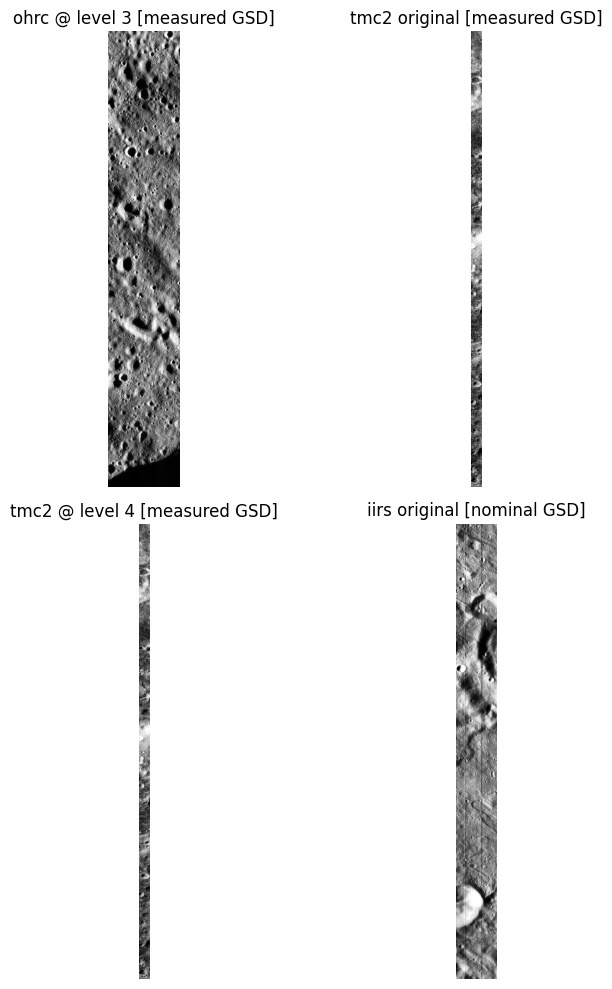

In [4]:
def load_gray_decimated(path, max_dim=1200):
    with rasterio.open(path) as src:
        scale = max(1, max(src.height, src.width) // max_dim)
        return src.read(1, out_shape=(src.height // scale, src.width // scale))

fig, axes = plt.subplots(len(scalespace_manifest), 2, figsize=(10, 5 * len(scalespace_manifest)))
if len(scalespace_manifest) == 1:
    axes = axes.reshape(1, 2)

for row_i, m in enumerate(scalespace_manifest):
    fine_img = load_gray_decimated(m['fine_scaled_path'])
    coarse_img = load_gray_decimated(m['coarse_path'])

    axes[row_i, 0].imshow(fine_img, cmap='gray')
    axes[row_i, 0].set_title(f"{m['fine_instrument']} @ level {m['pyramid_level_applied']} "
                              f"[{m['fine_gsd_source']} GSD]")
    axes[row_i, 0].axis('off')

    axes[row_i, 1].imshow(coarse_img, cmap='gray')
    axes[row_i, 1].set_title(f"{m['coarse_instrument']} original "
                              f"[{m['coarse_gsd_source']} GSD]")
    axes[row_i, 1].axis('off')

plt.tight_layout(); plt.show()

In [5]:
out_manifest = f'{DRIVE_ROOT}/processed/manifest_scalespace.csv'
with open(out_manifest, 'w', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=scalespace_manifest[0].keys())
    writer.writeheader()
    writer.writerows(scalespace_manifest)
print('Saved', out_manifest)


Saved /content/drive/MyDrive/26166_DATA/processed/manifest_scalespace.csv


---
### Notes
- IIRS will always show `[nominal GSD]` in this download since it has no
  geometry CSV to measure from — that's expected, not a bug.
- Next notebook: **05_correspondence_matching.ipynb**
